In [1]:
import sys

sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

data = get_runs_data(
    tag="conditions-vary-v",
    project="memorization",
    metrics=[
        "train/exact_match_embed_cond",
    ],
)
data = data[data["cfg.training.max_steps"] != 1000]                                                                                                                                                  
show_config_differences(data)

wandb: Currently logged in as: r-alvarezlucendo16 (minigpttu) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Found 24 runs with tag 'conditions-vary-v'


,cfg.dataset.npz_path,cfg.dataset_metadata.seed,cfg.dataset_metadata.strategy,cfg.dataset_metadata.vocab_size,cfg.dataset_metadata.target_level
_run_id,,,,,
2ewpupph,datasets/conditions-vary-v/level2a_random_look...,0,random,10000,2a
5qvr2p7e,datasets/conditions-vary-v/level0_lookup_V10_N...,0,None,10,0
78ua2ylb,datasets/conditions-vary-v/level0_lookup_V1000...,0,None,10000,0
85u82sue,datasets/conditions-vary-v/level2a_random_look...,2,random,10000,2a
94dhzzak,datasets/conditions-vary-v/level1_lookup_pos2_...,0,None,100,1
9wpdonfi,datasets/conditions-vary-v/level0_lookup_V1000...,0,None,1000,0
aln9qd8s,datasets/conditions-vary-v/level1_lookup_pos2_...,0,None,10000,1
gk83z51u,datasets/conditions-vary-v/level2a_random_look...,0,random,10,2a
huudode3,datasets/conditions-vary-v/level2a_random_look...,1,random,10000,2a


In [2]:
LEVEL_COL = "cfg.dataset_metadata.target_level"
STRATEGY_COL = "cfg.dataset_metadata.strategy"
METRIC_NAME = "train/exact_match_embed_cond"
STEP_COL = "train/global_step"
VOCAB_SIZE_COL = "cfg.dataset_metadata.vocab_size"
NUM_SAMPLES_COL = "cfg.dataset_metadata.num_samples"


def plot_runs(vocab_size, max_step=4000):
    filtered_data = data[data[VOCAB_SIZE_COL] == vocab_size]
    filtered_data = filtered_data[filtered_data[STEP_COL] <= max_step]

    if filtered_data.empty:
        print(f"No data found for vocab_size={vocab_size}")
        return

    # Aggregate by level, strategy, and step (across seeds)
    groups = (
        filtered_data.groupby(
            [LEVEL_COL, STRATEGY_COL, STEP_COL], dropna=False
        )[METRIC_NAME]
        .agg(["mean", "std"])
        .reset_index()
    )

    num_samples = filtered_data[NUM_SAMPLES_COL].iloc[0]

    plt.figure(figsize=(10, 6))
    for (level, strategy), g in groups.groupby(
        [LEVEL_COL, STRATEGY_COL], dropna=False
    ):
        label = f"Level {level}"
        if level == "2a":
            label += f" - {strategy}"

        steps = g[STEP_COL]
        mean = g["mean"]
        std = g["std"].fillna(0)

        plt.plot(steps, mean, label=label)
        plt.fill_between(
            steps, (mean - std).clip(0, 1), (mean + std).clip(0, 1), alpha=0.2
        )

    plt.xlabel("Training Steps", fontsize=16)
    plt.ylabel("Exact Match", fontsize=16)
    plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=14)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.title(
        f"Memorization curves with V={vocab_size} (N={int(num_samples)})",
        fontsize=18,
    )
    plt.show()
    # plt.savefig(f"plots/conditions_vary_v_{vocab_size}.pdf", bbox_inches="tight")

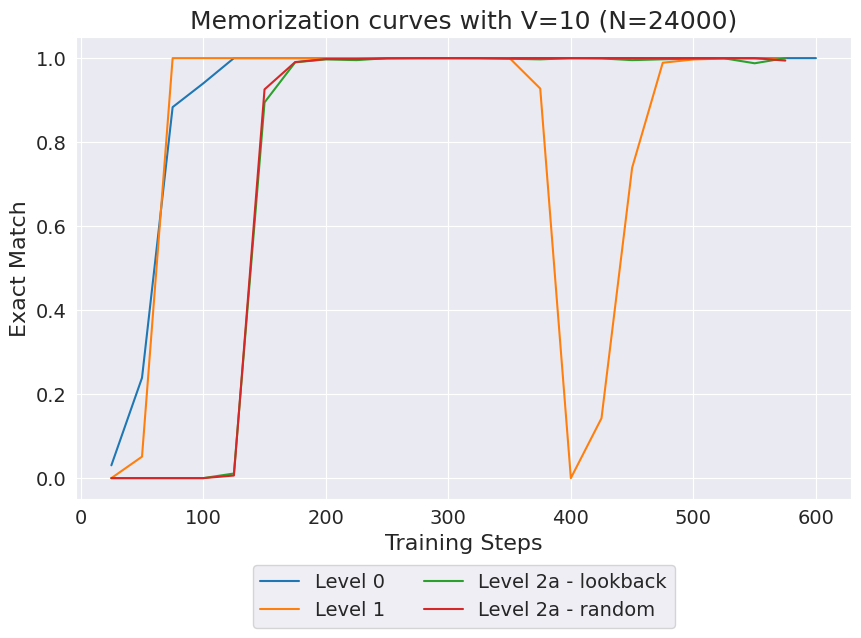

In [3]:
plot_runs(vocab_size=10, max_step=1000)

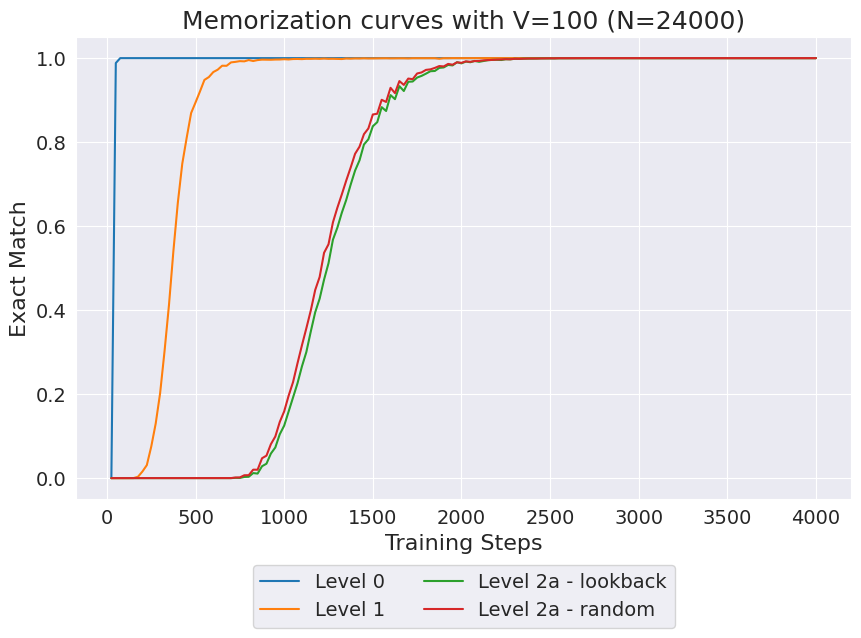

In [4]:
plot_runs(vocab_size=100)

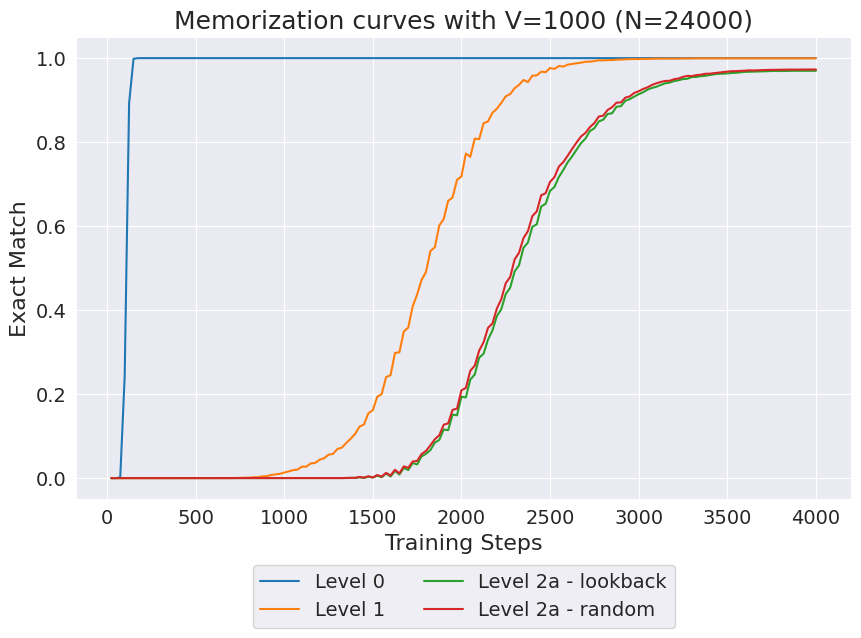

In [5]:
plot_runs(vocab_size=1000)

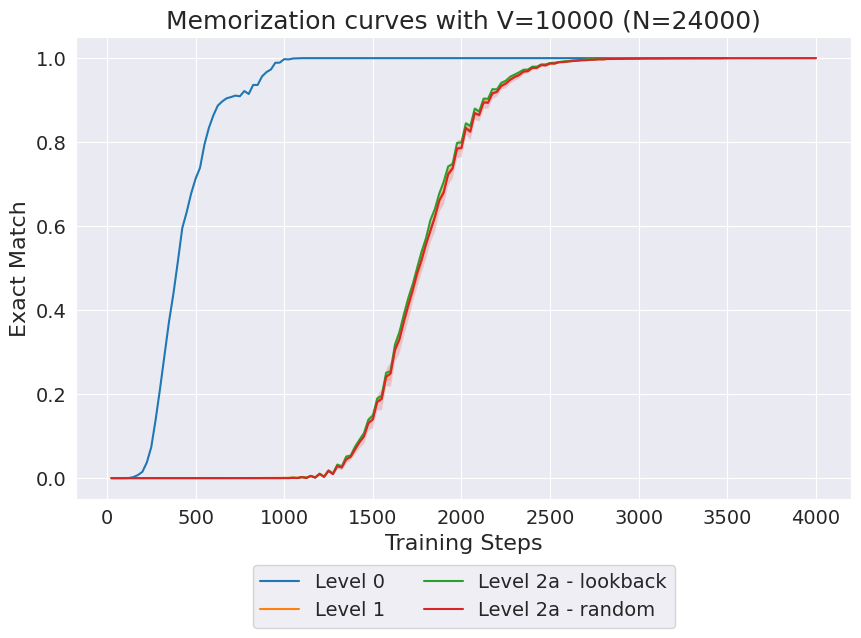

In [6]:
plot_runs(vocab_size=10000)

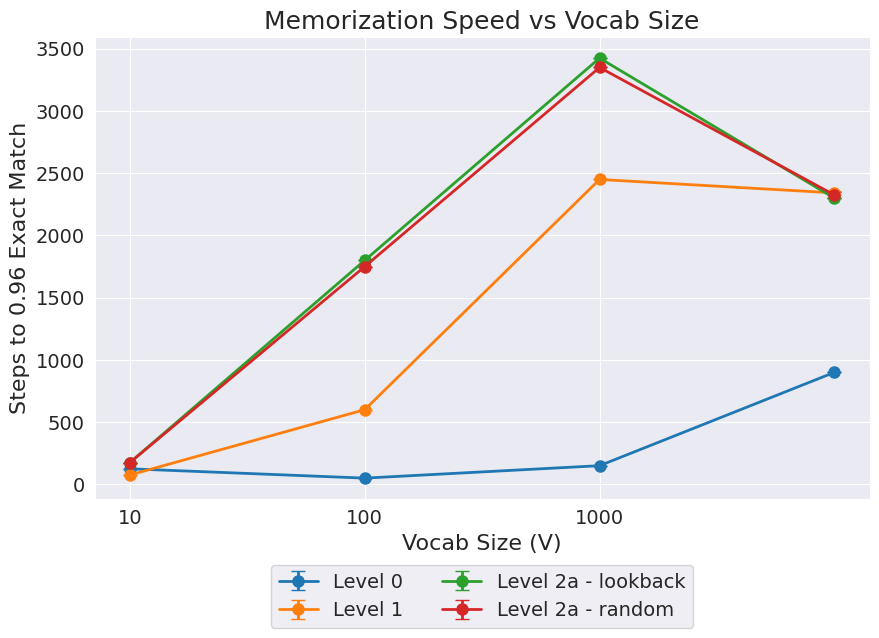

In [11]:
THRESHOLD = 0.96

def steps_to_threshold(group, threshold=THRESHOLD):
    """Return the first step where the metric reaches the threshold."""
    sorted_group = group.sort_values(STEP_COL)
    reached = sorted_group[sorted_group[METRIC_NAME] >= threshold]
    if len(reached) > 0:
        return reached[STEP_COL].iloc[0]
    return float("nan")

# Compute steps-to-threshold per run
threshold_results = []
for (run_id, level, strategy, vocab_size), group in data.groupby(
    ["_run_id", LEVEL_COL, STRATEGY_COL, VOCAB_SIZE_COL], dropna=False
):
    step = steps_to_threshold(group)
    label = f"Level {level}"
    if level == "2a":
        label += f" - {strategy}"
    threshold_results.append({
        "vocab_size": vocab_size,
        "level": level,
        "strategy": strategy,
        "label": label,
        "steps_to_threshold": step,
    })

import pandas as pd
threshold_df = pd.DataFrame(threshold_results)

# Aggregate across seeds
summary = (
    threshold_df.groupby(["vocab_size", "label"])["steps_to_threshold"]
    .agg(["mean", "std"])
    .reset_index()
)
summary["std"] = summary["std"].fillna(0)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
for label, g in summary.groupby("label"):
    g = g.sort_values("vocab_size")
    ax.errorbar(
        g["vocab_size"], g["mean"], yerr=g["std"],
        marker="o", capsize=5, linewidth=2, markersize=8, label=label,
    )

ax.set_xscale("log")
ax.set_xlabel("Vocab Size (V)", fontsize=16)
ax.set_ylabel(f"Steps to {THRESHOLD} Exact Match", fontsize=16)
ax.set_title("Memorization Speed vs Vocab Size", fontsize=18)
ax.set_xticks([10, 100, 1000])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.tick_params(labelsize=14)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=14)
# plt.savefig("plots/conditions_vary_v_summary.pdf", bbox_inches="tight")
plt.show()